In [35]:
import kagglehub
path = kagglehub.dataset_download("sh6147782/winequalityred")

Using Colab cache for faster access to the 'winequalityred' dataset.


In [36]:
import os
os.listdir(path)

['winequality-red.csv']

In [37]:
import pandas as pd
df=pd.read_csv(path+'/winequality-red.csv')

In [38]:
df.shape

(1596, 12)

In [39]:
df.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


In [40]:
df['quality'].value_counts()

,count
quality,
5,680
6,637
7,199
4,52
8,18
3,10


## Most of the wines belong to quality 5 followed by quality 6

In [41]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1596 entries, 0 to 1595
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1596 non-null   float64
 1   volatile acidity      1596 non-null   float64
 2   citric acid           1596 non-null   float64
 3   residual sugar        1596 non-null   float64
 4   chlorides             1596 non-null   float64
 5   free sulfur dioxide   1596 non-null   float64
 6   total sulfur dioxide  1596 non-null   float64
 7   density               1596 non-null   float64
 8   pH                    1596 non-null   float64
 9   sulphates             1596 non-null   float64
 10  alcohol               1596 non-null   float64
 11  quality               1596 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 149.8 KB


In [42]:
df.describe()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,1596.000000,1596.000000,1596.000000,1596.000000,1596.000000,1596.000000,1596.000000,1596.000000,1596.000000,1596.000000,1596.000000,1596.000000
mean,8.314160,0.527954,0.270276,2.535558,0.087120,15.858396,46.382206,0.996744,3.311917,0.656385,10.421147,5.637218
std,1.732203,0.179176,0.193894,1.405515,0.045251,10.460554,32.839138,0.001888,0.153346,0.163057,1.060371,0.807080
min,4.600000,0.120000,0.000000,0.900000,0.012000,1.000000,6.000000,0.990070,2.860000,0.330000,8.400000,3.000000
25%,7.100000,0.390000,0.090000,1.900000,0.070000,7.000000,22.000000,0.995600,3.210000,0.550000,9.500000,5.000000
50%,7.900000,0.520000,0.260000,2.200000,0.079000,14.000000,38.000000,0.996745,3.310000,0.620000,10.200000,6.000000
75%,9.200000,0.640000,0.420000,2.600000,0.090000,21.000000,62.000000,0.997833,3.400000,0.730000,11.100000,6.000000
max,15.600000,1.580000,0.790000,15.500000,0.611000,72.000000,289.000000,1.003690,4.010000,1.980000,14.000000,8.000000


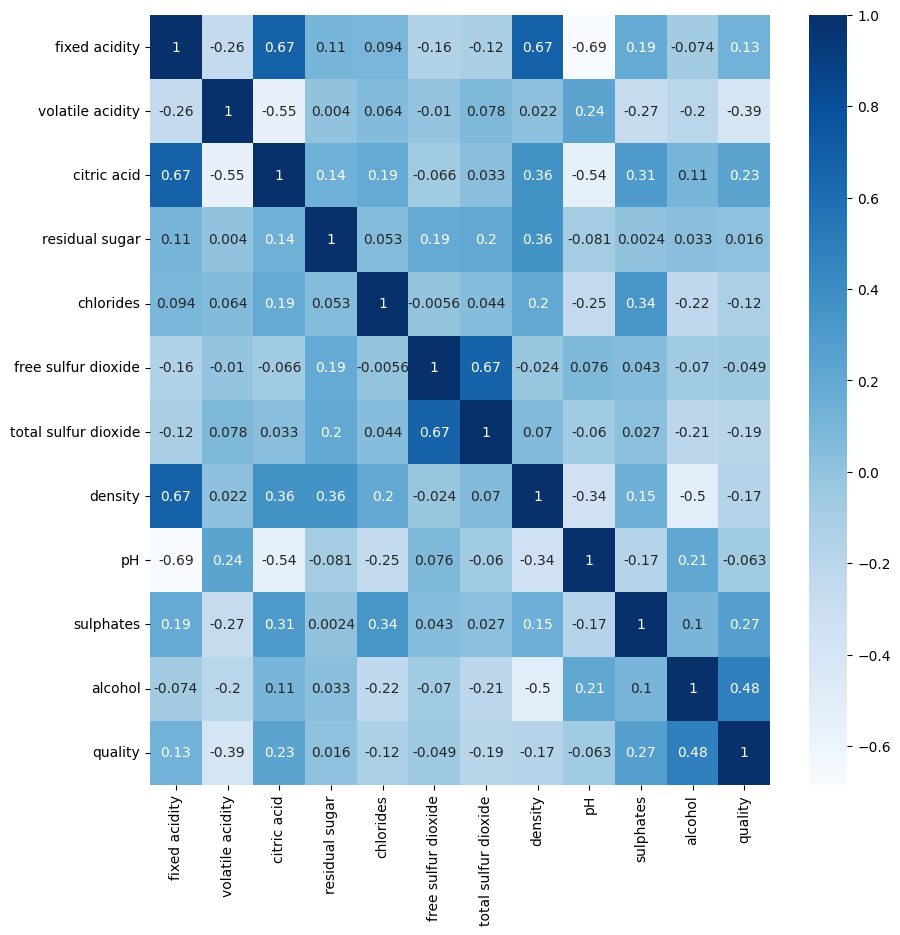

In [43]:
import seaborn as sns
import matplotlib.pyplot as plt
corr=df.corr()
plt.figure(figsize=(10,10))
sns.heatmap(corr,cmap='Blues',annot=True)
plt.show()

## Alcohol is playing most vital role in prediction of qualityy of wine and least role is played by volatile acidity.

In [44]:
df.isnull().sum()

,0
fixed acidity,0
volatile acidity,0
citric acid,0
residual sugar,0
chlorides,0
free sulfur dioxide,0
total sulfur dioxide,0
density,0
pH,0
sulphates,0


In [45]:
df.duplicated().sum()

np.int64(239)

In [46]:
df.drop_duplicates(inplace=True)

In [47]:
df.shape

(1357, 12)

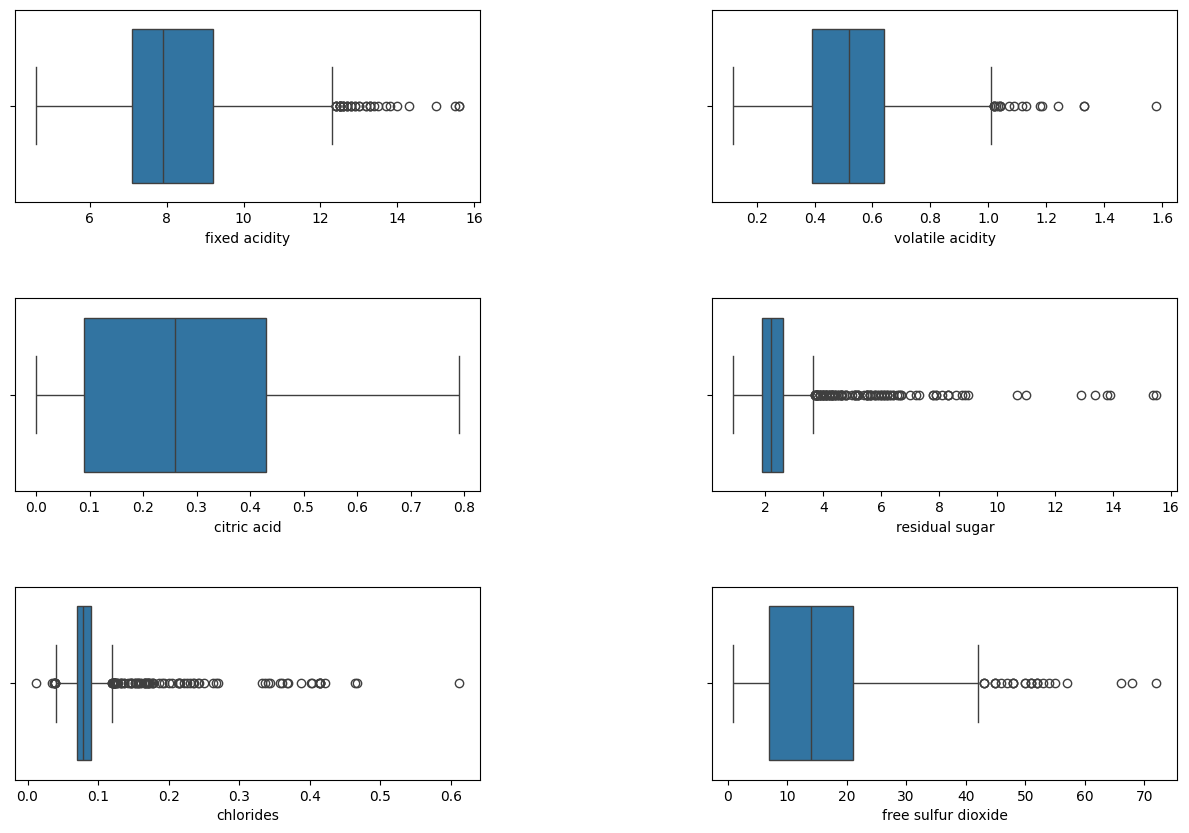

In [48]:
fig,ax=plt.subplots(3,2,figsize=(15,10))
sns.boxplot(df,x='fixed acidity',ax=ax[0,0],fill=True)
sns.boxplot(df,x='volatile acidity',ax=ax[0,1],fill=True)
sns.boxplot(df,x='citric acid',ax=ax[1,0],fill=True)
sns.boxplot(df,x='residual sugar',ax=ax[1,1],fill=True)
sns.boxplot(df,x='chlorides',ax=ax[2,0],fill=True)
sns.boxplot(df,x='free sulfur dioxide',ax=ax[2,1],fill=True)
plt.subplots_adjust(wspace=0.5,hspace=0.5)
plt.show()

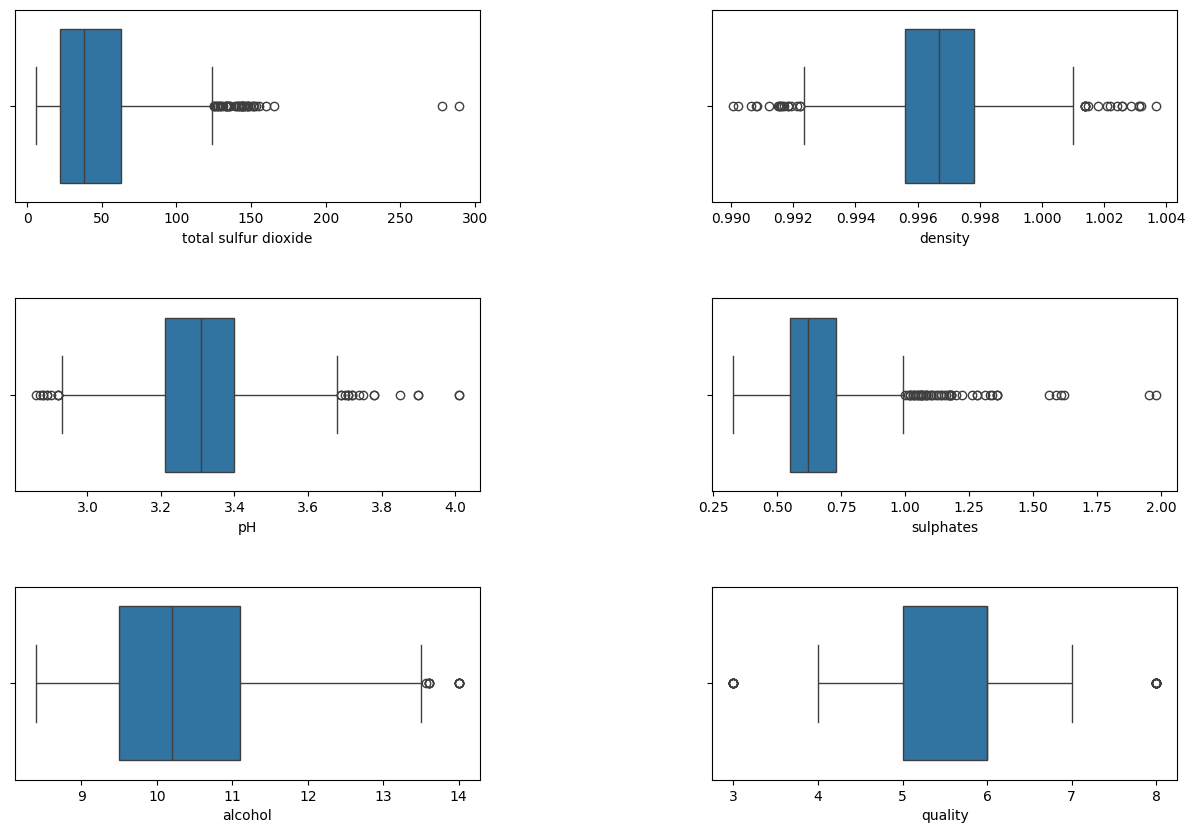

In [49]:
fig,ax=plt.subplots(3,2,figsize=(15,10))
sns.boxplot(df,x='total sulfur dioxide',ax=ax[0,0],fill=True)
sns.boxplot(df,x='density',ax=ax[0,1],fill=True)
sns.boxplot(df,x='pH',ax=ax[1,0],fill=True)
sns.boxplot(df,x='sulphates',ax=ax[1,1],fill=True)
sns.boxplot(df,x='alcohol',ax=ax[2,0],fill=True)
sns.boxplot(df,x='quality',ax=ax[2,1],fill=True)
plt.subplots_adjust(wspace=0.5,hspace=0.5)
plt.show()

From the following, we can get insights that the column total sulfur dioxide only has the outliers i.e. 2 datapoints above 200 around 300.

In [51]:
df=df[df['total sulfur dioxide']<=200]

In [52]:
df.columns

Index(['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar',
       'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density',
       'pH', 'sulphates', 'alcohol', 'quality'],
      dtype='object')

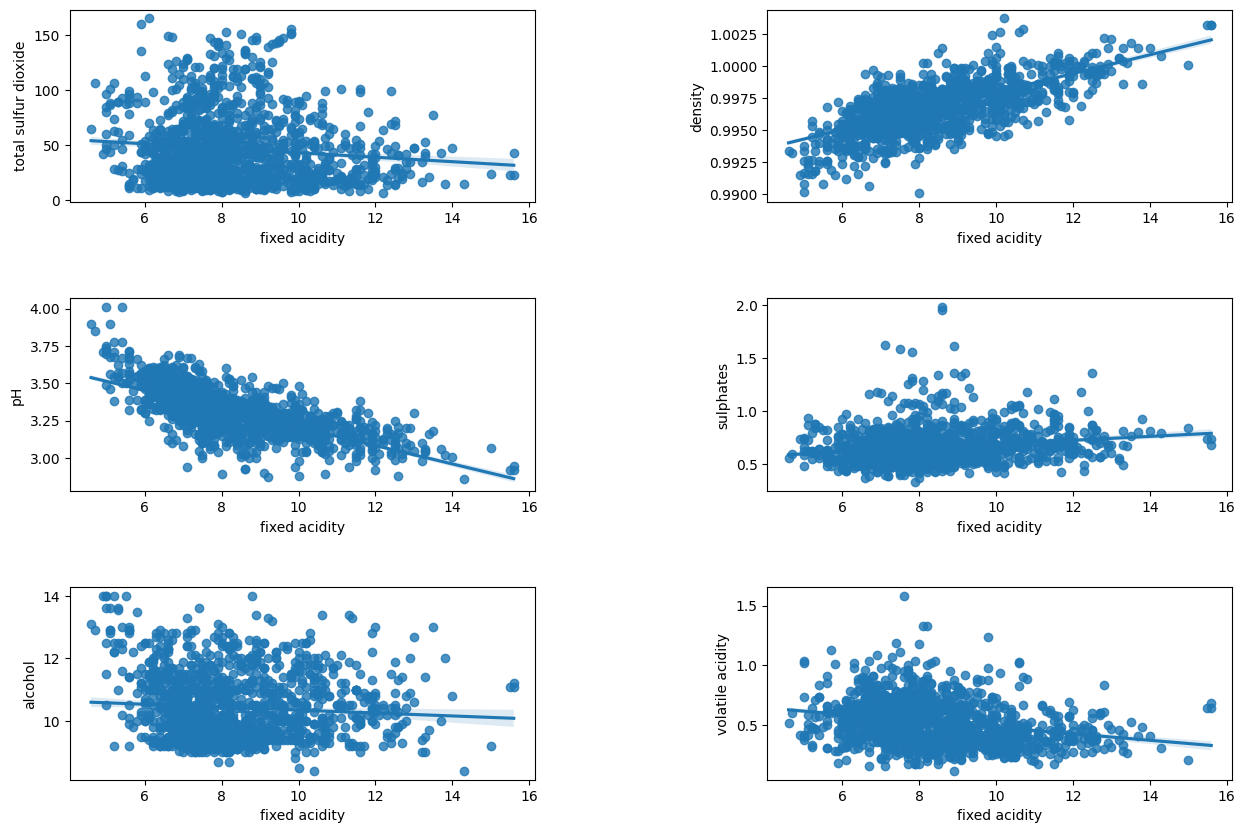

In [55]:
fig,ax=plt.subplots(3,2,figsize=(15,10))
sns.regplot(df,x='fixed acidity',y='total sulfur dioxide',ax=ax[0,0])
sns.regplot(df,x='fixed acidity',y='density',ax=ax[0,1])
sns.regplot(df,x='fixed acidity',y='pH',ax=ax[1,0])
sns.regplot(df,x='fixed acidity',y='sulphates',ax=ax[1,1])
sns.regplot(df,x='fixed acidity',y='alcohol',ax=ax[2,0])
sns.regplot(df,x='fixed acidity',y='volatile acidity',ax=ax[2,1])
plt.subplots_adjust(wspace=0.5,hspace=0.5)
plt.show()

## With increase in fixed acidity, density is linearly increasing and pH is inversely to fixed acidity.

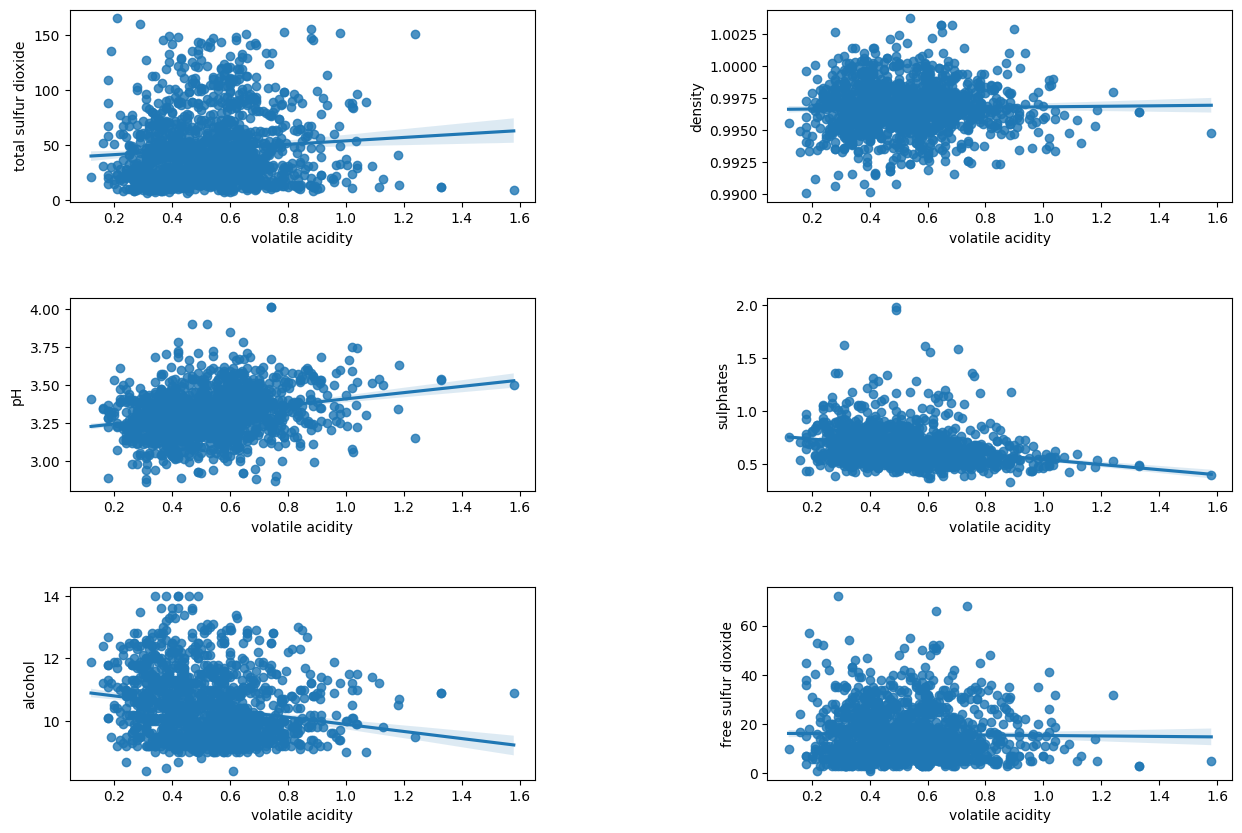

In [56]:
fig,ax=plt.subplots(3,2,figsize=(15,10))
sns.regplot(df,x='volatile acidity',y='total sulfur dioxide',ax=ax[0,0])
sns.regplot(df,x='volatile acidity',y='density',ax=ax[0,1])
sns.regplot(df,x='volatile acidity',y='pH',ax=ax[1,0])
sns.regplot(df,x='volatile acidity',y='sulphates',ax=ax[1,1])
sns.regplot(df,x='volatile acidity',y='alcohol',ax=ax[2,0])
sns.regplot(df,x='volatile acidity',y='free sulfur dioxide',ax=ax[2,1])
plt.subplots_adjust(wspace=0.5,hspace=0.5)
plt.show()

## PH is quite linearly increasing with volatile acidity

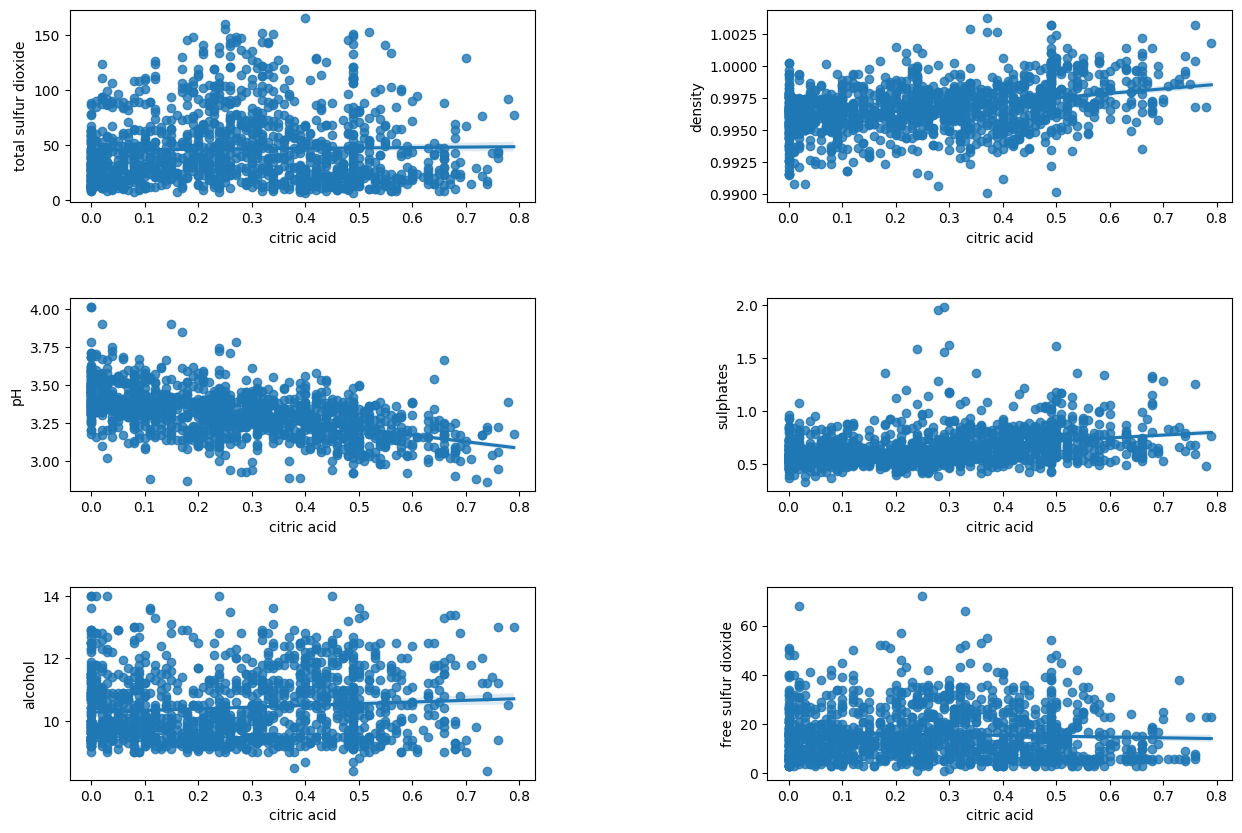

In [57]:
fig,ax=plt.subplots(3,2,figsize=(15,10))
sns.regplot(df,x='citric acid',y='total sulfur dioxide',ax=ax[0,0])
sns.regplot(df,x='citric acid',y='density',ax=ax[0,1])
sns.regplot(df,x='citric acid',y='pH',ax=ax[1,0])
sns.regplot(df,x='citric acid',y='sulphates',ax=ax[1,1])
sns.regplot(df,x='citric acid',y='alcohol',ax=ax[2,0])
sns.regplot(df,x='citric acid',y='free sulfur dioxide',ax=ax[2,1])
plt.subplots_adjust(wspace=0.5,hspace=0.5)
plt.show()

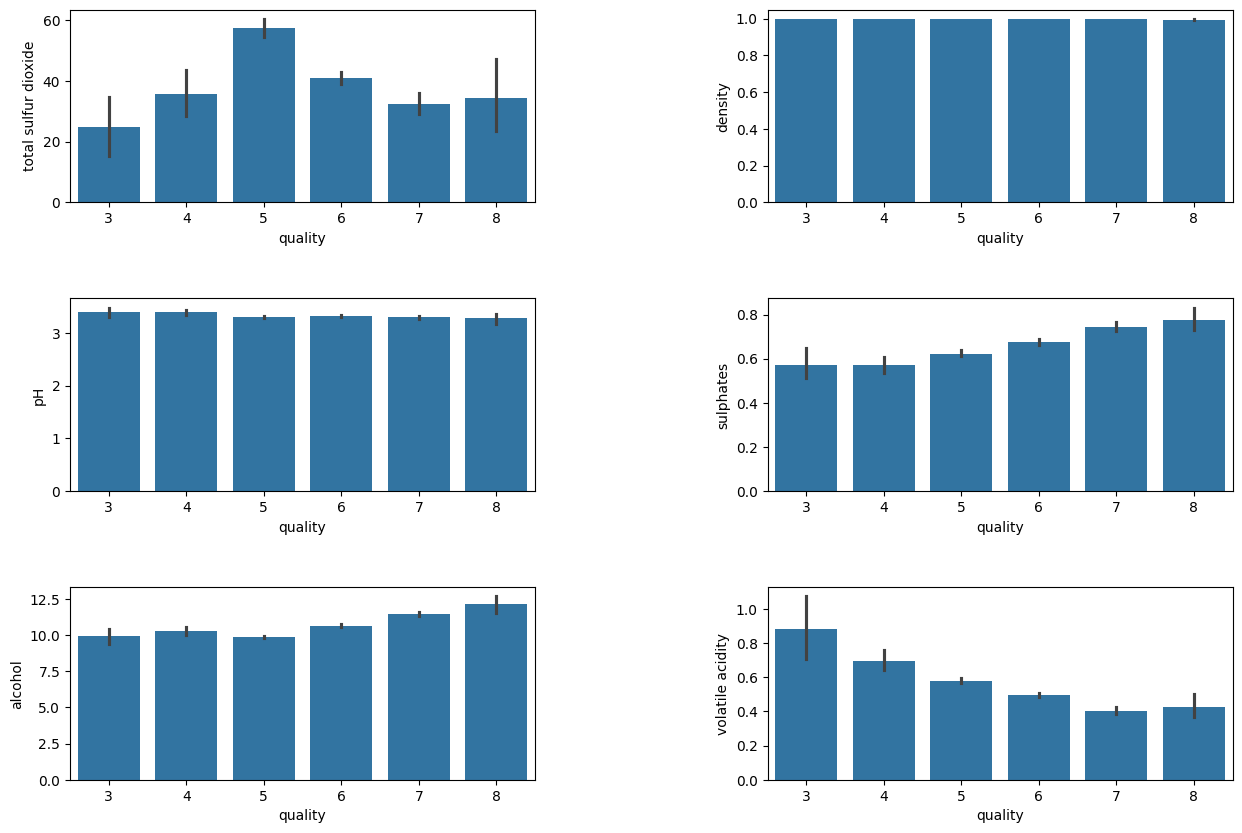

In [58]:
fig,ax=plt.subplots(3,2,figsize=(15,10))
sns.barplot(df,x='quality',y='total sulfur dioxide',ax=ax[0,0])
sns.barplot(df,x='quality',y='density',ax=ax[0,1])
sns.barplot(df,x='quality',y='pH',ax=ax[1,0])
sns.barplot(df,x='quality',y='sulphates',ax=ax[1,1])
sns.barplot(df,x='quality',y='alcohol',ax=ax[2,0])
sns.barplot(df,x='quality',y='volatile acidity',ax=ax[2,1])
plt.subplots_adjust(wspace=0.5,hspace=0.5)
plt.show()

## Wine quality improves from 2 to 8.
## total sulfur dioxide is maximum for quality 5 wine.
## density and pH is same for all qualities of wines
## sulphates are increasing as the quality of wines is increasing i.e. as wine reaches 8, it has maximum sulphates composition.
## As the alcoholic content is increasing the quality of alcohol also increases.
## As the volatile acidity decreases, the quality of wine increases.

In [60]:
x=df.drop(columns=['quality'])
y=df['quality']

In [62]:
x.shape,y.shape

((1355, 11), (1355,))

In [66]:
from sklearn.preprocessing import StandardScaler
scaler=StandardScaler()
x=scaler.fit_transform(x)

In [67]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)

In [68]:
x_train.shape,x_test.shape,y_train.shape,y_test.shape

((1084, 11), (271, 11), (1084,), (271,))

In [79]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import AdaBoostClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score,classification_report

In [82]:
models={
    'Random Forest':RandomForestClassifier(),
    'KNN':KNeighborsClassifier(),
    'Naive Bayes':GaussianNB(),
    'SVM':SVC(),
    'AdaBoost':AdaBoostClassifier()
}
scores={}
for i in range(len(list(models))):
  model=list(models.values())[i]
  model.fit(x_train,y_train)
  y_train_pred=model.predict(x_train)
  y_test_pred=model.predict(x_test)
  model_train_accuracy=accuracy_score(y_train,y_train_pred)
  model_test_accuracy=accuracy_score(y_test,y_test_pred)
  scores[list(models)[i]+'_Train']=model_train_accuracy
  scores[list(models)[i]+'_Test']=model_test_accuracy
  print(f'For {list(models)[i]} : ')
  print(f'Training Report : {classification_report(y_train,y_train_pred)}\n')
  print(f'Testing Report : {classification_report(y_test,y_test_pred)}\n\n')

For Random Forest : 
Training Report :               precision    recall  f1-score   support

           3       1.00      1.00      1.00         9
           4       1.00      1.00      1.00        37
           5       1.00      1.00      1.00       464
           6       1.00      1.00      1.00       437
           7       1.00      1.00      1.00       125
           8       1.00      1.00      1.00        12

    accuracy                           1.00      1084
   macro avg       1.00      1.00      1.00      1084
weighted avg       1.00      1.00      1.00      1084


Testing Report :               precision    recall  f1-score   support

           3       0.00      0.00      0.00         1
           4       0.00      0.00      0.00        15
           5       0.69      0.72      0.71       112
           6       0.52      0.69      0.59        98
           7       0.64      0.35      0.45        40
           8       0.00      0.00      0.00         5

    accuracy        

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/m

For AdaBoost : 
Training Report :               precision    recall  f1-score   support

           3       0.00      0.00      0.00         9
           4       0.00      0.00      0.00        37
           5       0.66      0.46      0.54       464
           6       0.47      0.75      0.57       437
           7       0.48      0.21      0.29       125
           8       0.00      0.00      0.00        12

    accuracy                           0.52      1084
   macro avg       0.27      0.24      0.23      1084
weighted avg       0.53      0.52      0.50      1084


Testing Report :               precision    recall  f1-score   support

           3       0.00      0.00      0.00         1
           4       0.00      0.00      0.00        15
           5       0.65      0.49      0.56       112
           6       0.40      0.70      0.51        98
           7       0.36      0.12      0.19        40
           8       0.00      0.00      0.00         5

    accuracy             

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/m

In [81]:
pd.DataFrame(list(scores.values()),index=list(scores))

,0
Random Forest_Train,1.000000
Random Forest_Test,0.583026
KNN_Train,0.666052
KNN_Test,0.538745
Naive Bayes_Train,0.541513
Naive Bayes_Test,0.523985
SVM_Train,0.661439
SVM_Test,0.616236
AdaBoost_Train,0.523063
AdaBoost_Test,0.476015


## Random Forest is leading to overfitting
## Best model is coming out to be SVC

In [98]:
model=SVC(kernel='rbf',C=1,gamma=0.1)
model.fit(x_train,y_train)
y_train_pred=model.predict(x_train)
y_test_pred=model.predict(x_test)
train_accuracy=accuracy_score(y_train,y_train_pred)
test_accuracy=accuracy_score(y_test,y_test_pred)
print(f'Training Accuracy : {train_accuracy}')
print(f'Testing Accuracy : {test_accuracy}')

Training Accuracy : 0.6632841328413284
Testing Accuracy : 0.6199261992619927


In [99]:
df.sample()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
295,7.1,0.63,0.06,2.0,0.083,8.0,29.0,0.99855,3.67,0.73,9.6,5


In [102]:
import numpy as np
input=(7.1,	0.63,	0.06,	2.0,	0.083,	8.0,	29.0,	0.99855,	3.67,	0.73,	9.6	)
input=np.array(input).reshape(1,-1)
scaled_input=scaler.transform(input)
model.predict(scaled_input)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


array([5])

In [107]:
import pickle as pkl
with open('model.pkl','wb') as f:
  pkl.dump(model,f)

In [108]:
with open('scaler.pkl','wb') as f:
  pkl.dump(scaler,f)